# Chapter 05 & 06 — Propensity Scores, IPW & Doubly Robust Estimation
> *Reference: Paraphrased from Matheus Facure's Causal Inference in Python (Chapters 5 & 6).*

When treatment assignment is non-random, Inverse Probability Weighting (IPW) and Doubly Robust / Augmented IPW (AIPW)
allow us to balance covariates and estimate causal effects under conditional exchangeability.
This notebook explores:
1. **Confounded Observational Studies**: Management training on employee engagement (`management_training.csv`).
2. **Propensity Score Diagnostics**: Overlap and common support via `.plot_propensity()`.
3. **Covariate Balance & Love Plot**: Evaluating pre- and post-weighting standardized mean differences via `.love_plot()`.
4. **Inverse Probability Weighting (IPW)** for ATE and ATT.
5. **Augmented IPW (Doubly Robust AIPW)**: Combining propensity weights with outcome regression models for double protection.
6. **Causal Treatment Effect Distribution**: First-class `StudentsT` inference.

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from make_data import load_management_training
from probability.distributions import Ratio, Boolean, StudentsT
from probability.models import IPW, AIPW, DoublyRobust

## 5.1 The Management Training Dataset
We want to estimate the causal effect of an intensive management training program (`intervention`) on team `engagement_score`.
Managers self-selected or were selected based on `tenure`, `n_of_reports`, `gender`, `last_engagement_score`, `department_score`, and `department_size`.

In [2]:
mgt_df = load_management_training().dropna()
print(f"Sample size: {len(mgt_df)} managers")
print(f"Training participation rate: {mgt_df['intervention'].mean():.1%}")
mgt_df[['intervention', 'engagement_score', 'tenure', 'n_of_reports', 'last_engagement_score']].head()

Sample size: 10391 managers
Training participation rate: 54.0%


,intervention,engagement_score,tenure,n_of_reports,last_engagement_score
0,1,0.277359,6,4,0.614261
1,1,-0.449646,4,8,0.069636
2,1,0.769703,6,4,0.866918
3,1,-0.121763,6,4,0.029071
4,1,1.526147,6,4,0.589857


### Raw Unadjusted Difference
A simple comparison of means shows a naive difference that is confounded by baseline department score and past engagement.

In [3]:
y_treated = mgt_df[mgt_df['intervention'] == 1]['engagement_score'].mean()
y_control = mgt_df[mgt_df['intervention'] == 0]['engagement_score'].mean()
print(f"Treated Mean Engagement: {y_treated:.3f}")
print(f"Control Mean Engagement: {y_control:.3f}")
print(f"Raw Unadjusted Difference: {y_treated - y_control:.3f}")

Treated Mean Engagement: 0.200
Control Mean Engagement: -0.235
Raw Unadjusted Difference: 0.435


## 5.2 Inverse Probability Weighting (IPW)
We fit a logistic propensity score model $P(T=1 \mid X)$ and calculate normalized (Hajek) IPW weights.

In [4]:
covariate_cols = [
    'tenure', 'n_of_reports', 'gender', 'last_engagement_score',
    'department_score', 'department_size'
]
ipw_ate = IPW.fit(
    treatment=mgt_df['intervention'],
    outcome=mgt_df['engagement_score'],
    covariates=mgt_df[covariate_cols],
    estimand='ATE'
)
print('--- IPW ATE Estimation ---')
ipw_ate.summary().round(3)

--- IPW ATE Estimation ---


,estimate,std_err,t_stat,p_value,95% CI lower,95% CI upper,n_obs
estimand,,,,,,,
ATE,0.27,0.02,13.528,0.0,0.231,0.309,10391


## 5.3 Covariate Balance Diagnostics & Love Plot
A Love plot compares the absolute standardized mean difference (Cohen's d) for each covariate before and after weighting.
Balance is considered achieved when weighted differences fall below the standard threshold of $0.10$.

In [5]:
bal_summary = ipw_ate.balance_summary()
print('--- Covariate Balance Summary Table ---')
bal_summary.round(4)

--- Covariate Balance Summary Table ---


,unweighted_diff,weighted_diff,abs_unweighted,abs_weighted,balanced
covariate,,,,,
tenure,0.4063,-0.0001,0.4063,0.0001,True
n_of_reports,0.0010,0.0000,0.0010,0.0000,True
gender,-0.0629,-0.0000,0.0629,0.0000,True
last_engagement_score,0.2100,-0.0000,0.2100,0.0000,True
department_score,-0.1325,-0.0003,0.1325,0.0003,True
department_size,0.1276,-0.0001,0.1276,0.0001,True


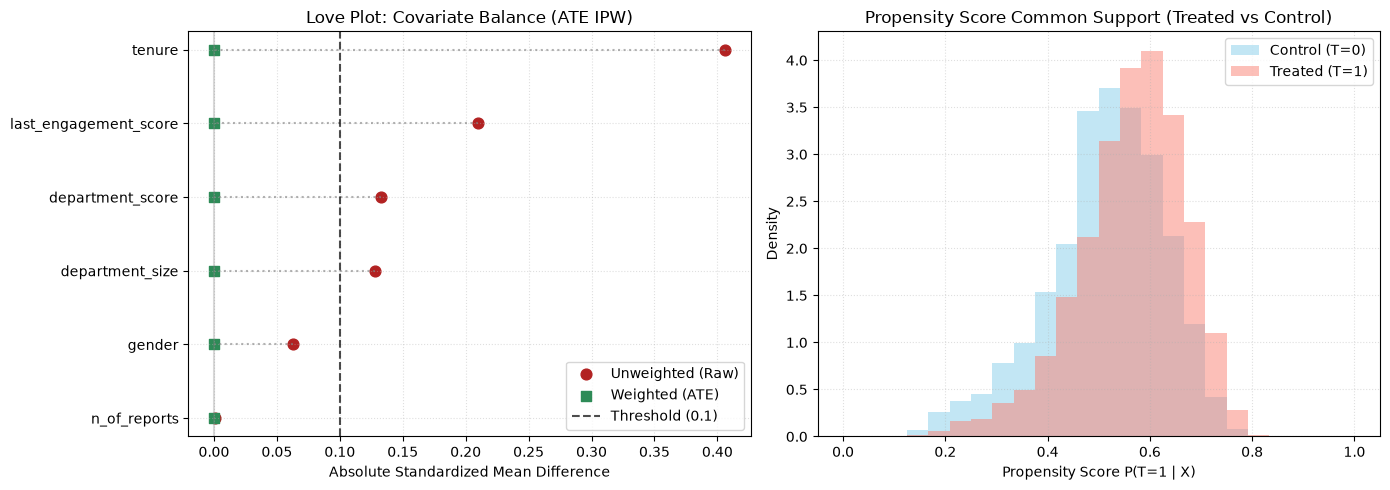

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ipw_ate.love_plot(
    threshold=0.10,
    ax=axes[0],
    title="Love Plot: Covariate Balance (ATE IPW)"
)

ipw_ate.plot_propensity(
    ax=axes[1],
    title="Propensity Score Common Support (Treated vs Control)"
)

plt.tight_layout()

## 5.4 Augmented IPW (Doubly Robust Estimation)
AIPW combines outcome models $\mu_1(X) = E[Y \mid T=1, X]$ and $\mu_0(X) = E[Y \mid T=0, X]$ with the propensity score $e(X)$.
It has the **Doubly Robust** property: consistent if EITHER the outcome model OR the propensity model is correctly specified.

In [7]:
aipw = AIPW.fit(
    treatment=mgt_df['intervention'],
    outcome=mgt_df['engagement_score'],
    covariates=mgt_df[covariate_cols],
    estimand='ATE'
)
print('--- Doubly Robust (AIPW) Treatment Effect ---')
aipw.summary().round(3)

--- Doubly Robust (AIPW) Treatment Effect ---


,estimate,std_err,t_stat,p_value,95% CI lower,95% CI upper,n_obs
estimand,,,,,,,
ATE,0.277,0.018,15.271,0.0,0.241,0.312,10391


## 5.5 Treatment Effect Sampling Distribution (`StudentsT`)
We inspect the doubly robust causal effect as a probability distribution.

In [8]:
eff_dist = aipw.effect_distribution
print(f"Causal Effect Distribution: StudentsT(nu={eff_dist.nu:.0f}, mu={eff_dist.mu:.3f}, sigma={eff_dist.sigma:.3f})")
print(f"P(Treatment Effect > 0):    {float(eff_dist > 0):.4%}")
print(f"95% HDI / Confidence Interval: {eff_dist.interval(0.95)}")

Causal Effect Distribution: StudentsT(nu=10390, mu=0.277, sigma=0.018)
P(Treatment Effect > 0):    100.0000%
95% HDI / Confidence Interval: (np.float64(0.24102256542260825), np.float64(0.31200908388671533))
